In [1]:
import xmlrpc.client
import pickle
import datetime
from PIL import Image
from pylab import *
import numpy as np

%matplotlib inline

# Подключение к серверам
server = xmlrpc.client.ServerProxy("http://localhost:8008")
stats  = xmlrpc.client.ServerProxy("http://localhost:8018")

print(server.system.listMethods())

print('Ping:', server.ping())
print('Server datetime:', server.now())
print('View, type, value:', server.type(2))
print('View, type, value:', server.type(2.))
print('View, type, value:', server.type('My string'))
print('View, type, value:', server.type("My string"))
print('View, type, value:', server.type([1,2,3]))
print('View, type, value:', server.type(["one", "two", "three"]))
print('View, type, value:', server.type((1,2,"3")))
print('Sum 2 + 3 :', server.sum(2, 3))
print('Pow 2^3: ', server.pow(2, 3))

['binarize_image', 'black_list_check', 'cloud_percent', 'color_inversion', 'flip_vertical', 'now', 'ping', 'pow', 'sum', 'system.listMethods', 'system.methodHelp', 'system.methodSignature', 'type']
Ping: True
Server datetime: 20260928T22:43:39
View, type, value: ['2', "<class 'int'>", 2]
View, type, value: ['2.0', "<class 'float'>", 2.0]
View, type, value: ['My string', "<class 'str'>", 'My string']
View, type, value: ['My string', "<class 'str'>", 'My string']
View, type, value: ['[1, 2, 3]', "<class 'list'>", [1, 2, 3]]
View, type, value: ["['one', 'two', 'three']", "<class 'list'>", ['one', 'two', 'three']]
View, type, value: ["[1, 2, '3']", "<class 'list'>", [1, 2, '3']]
Sum 2 + 3 : 5
Pow 2^3:  8


In [1]:
import xmlrpc.client
stats = xmlrpc.client.ServerProxy("http://localhost:8018")

print("list_stats_methods:", stats.list_stats_methods())
print("ping_stats:", stats.ping_stats())
print("get_log():", stats.get_log())
print("get_log(event_type='binarize_image'):", stats.get_log(event_type='binarize_image'))

list_stats_methods: ['add_log', 'get_log', 'list_stats_methods', 'ping_stats', 'system.listMethods', 'system.methodHelp', 'system.methodSignature']
ping_stats: stats_server_ok
get_log(): [['black_list_check', '2026-09-28 22:43:41'], ['black_list_check', '2026-09-28 22:43:41'], ['black_list_check', '2026-09-28 22:43:41'], ['cloud_percent', '2026-09-28 22:43:47'], ['cloud_percent', '2026-09-28 22:43:47'], ['color_inversion', '2026-09-28 22:43:50'], ['color_inversion', '2026-09-28 22:43:50'], ['binarize_image', '2026-09-28 22:43:50'], ['binarize_image', '2026-09-28 22:43:51'], ['flip_vertical', '2026-09-28 22:43:51'], ['flip_vertical', '2026-09-28 22:43:51']]


TypeError: _Method.__call__() got an unexpected keyword argument 'event_type'

In [2]:
print("=== Пункт 1: Проверка чёрного списка ===")

# Точное совпадение, но другой регистр -> должно вернуть 'yes'
print(server.black_list_check('петров', 'иван', 'петрович', '07.08.1985'))

# Частичное совпадение — 1 буква отличается -> должно вернуть 'similar'
print(server.black_list_check('Петрова', 'Иван', 'Петрович', '07.08.1985'))

# Ещё один вариант частичного совпадения (Семён vs Семен)
print(server.black_list_check('Семёнов', 'Иван', 'Петрович', '07.08.1985'))

# Нет в списке -> 'no'
print(server.black_list_check('Семёнов', 'Пётр', 'Петрович', '01.01.2000'))

# Ещё тесты (как было в ЛР1)
print(server.black_list_check('Петров', 'Иван', 'Петрович', '07.08.1985'))
print(server.black_list_check('Приветов', 'Вася', 'Васильевич', '01.01.2000'))
print(server.black_list_check('Иванов', 'Иван', 'Иванович', '22.03.1989'))
print(server.black_list_check('Петров', 'Аркадий', 'Викторович', '01.01.2000'))

=== Пункт 1: Проверка чёрного списка ===
петров иван петрович 07.08.1985 : no
Петрова Иван Петрович 07.08.1985 : no
Семёнов Иван Петрович 07.08.1985 : no
Семёнов Пётр Петрович 01.01.2000 : no
Петров Иван Петрович 07.08.1985 : no
Приветов Вася Васильевич 01.01.2000 : no
Иванов Иван Иванович 22.03.1989 : yes
Петров Аркадий Викторович 01.01.2000 : no


In [3]:
# Подготовка изображений
img_color = Image.open('Jellyfish.jpg')
img_arr_color = np.array(img_color)

img_mono = Image.open('11.bmp')
img_arr_mono = np.array(img_mono)

print("Изображения загружены.")
print(f"Color image shape: {img_arr_color.shape}, dtype: {img_arr_color.dtype}")
print(f"Mono image shape: {img_arr_mono.shape}, dtype: {img_arr_mono.dtype}")

# Сериализация
pimg_color = xmlrpc.client.Binary(pickle.dumps(img_arr_color))
pimg_mono  = xmlrpc.client.Binary(pickle.dumps(img_arr_mono))

Изображения загружены.
Color image shape: (768, 1024, 3), dtype: uint8
Mono image shape: (780, 780), dtype: uint8


In [4]:
print("=== Пункт 2: Оценка процента облачности ===")
threshold = 128
cloud_color = server.cloud_percent(pimg_color, threshold)
cloud_mono  = server.cloud_percent(pimg_mono,  threshold)

print(f"Cloud percent (color): {cloud_color:.2f}%")
print(f"Cloud percent (mono):  {cloud_mono:.2f}%")

=== Пункт 2: Оценка процента облачности ===
Cloud percent (color): 8.89%
Cloud percent (mono):  1.18%


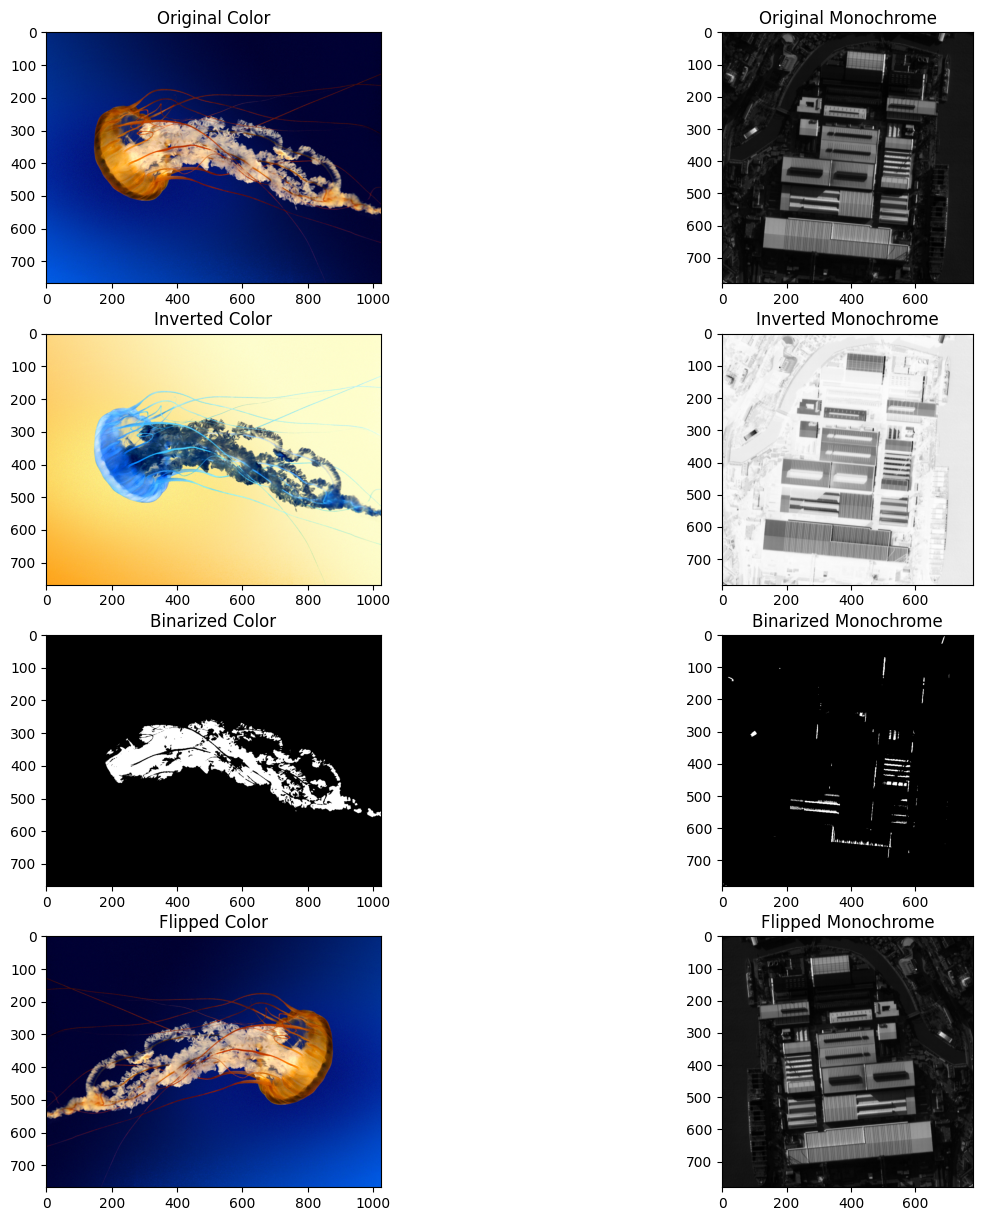

In [5]:
# Пункт 5 (ЛР1): Инверсия
img_bin2_color = server.color_inversion(pimg_color)
img_arr_inv_color = pickle.loads(img_bin2_color.data)

img_bin2_mono = server.color_inversion(pimg_mono)
img_arr_inv_mono = pickle.loads(img_bin2_mono.data)

# Пункт 6 (ЛР1): Бинаризация
threshold = 128
img_bin2_color_bw = server.binarize_image(pimg_color, threshold)
img_arr_bin_color = pickle.loads(img_bin2_color_bw.data)

img_bin2_mono_bw = server.binarize_image(pimg_mono, threshold)
img_arr_bin_mono = pickle.loads(img_bin2_mono_bw.data)

# Пункт 7 (ЛР1): Разворот по вертикали
img_bin2_color_flip = server.flip_vertical(pimg_color)
img_arr_flip_color = pickle.loads(img_bin2_color_flip.data)

img_bin2_mono_flip = server.flip_vertical(pimg_mono)
img_arr_flip_mono = pickle.loads(img_bin2_mono_flip.data)

# Отображение результатов
figure(figsize=(15, 15))

subplot(4, 2, 1); imshow(img_arr_color);            title("Original Color")
subplot(4, 2, 2); imshow(img_arr_mono, cmap='gray'); title("Original Monochrome")
subplot(4, 2, 3); imshow(img_arr_inv_color);         title("Inverted Color")
subplot(4, 2, 4); imshow(img_arr_inv_mono, cmap='gray'); title("Inverted Monochrome")
subplot(4, 2, 5); imshow(img_arr_bin_color);         title("Binarized Color")
subplot(4, 2, 6); imshow(img_arr_bin_mono, cmap='gray'); title("Binarized Monochrome")
subplot(4, 2, 7); imshow(img_arr_flip_color);        title("Flipped Color")
subplot(4, 2, 8); imshow(img_arr_flip_mono, cmap='gray'); title("Flipped Monochrome")

show()

In [17]:
print("=== Пункт 6: Журнал событий сервера статистики ===")

print("\n--- Все события ---")
all_events = stats.get_log()
for row in all_events[:30]:   # первые 30 для наглядности
    print(row)
print(f"... всего записей: {len(all_events)}")

print("\n--- Только black_list_check ---")
for row in stats.get_log(event_type='black_list_check'):
    print(row)

print("\n--- Только cloud_percent ---")
for row in stats.get_log(event_type='cloud_percent'):
    print(row)

print("\n--- Срез по времени: последние 30 минут ---")
dt_from = (datetime.datetime.now() - datetime.timedelta(minutes=30)).strftime("%Y-%m-%d %H:%M:%S")
dt_to   = datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
print(f"dt_from = {dt_from}, dt_to = {dt_to}")
for row in stats.get_log(dt_from=dt_from, dt_to=dt_to):
    print(row)

print("\n--- Комбинированный фильтр: cloud_percent за последние 30 минут ---")
for row in stats.get_log(event_type='cloud_percent', dt_from=dt_from, dt_to=dt_to):
    print(row)

=== Пункт 6: Журнал событий сервера статистики ===

--- Все события ---
['binarize_image', '2026-09-28 22:37:01']
['binarize_image', '2026-09-28 22:37:01']
['flip_vertical', '2026-09-28 22:37:01']
['flip_vertical', '2026-09-28 22:37:02']
... всего записей: 4

--- Только black_list_check ---


TypeError: _Method.__call__() got an unexpected keyword argument 'event_type'

In [ ]:
# Пункт 4: если stats-сервер выключен, основной сервер должен работать.
# Останови xmlrpc_stats_server.ipynb (Kernel -> Shutdown) и запусти эту ячейку.
print("=== Пункт 4: Работа при выключенном stats-сервере ===")
print("Sum 2 + 3 :", server.sum(2, 3))
print("Pow 2^3: ", server.pow(2, 3))
print("Ping:", server.ping())
print("Если ты видишь числа выше — п.4 работает корректно.")